In [1]:
from empi_pyspark_utils.spark_support.context import create_local_context
from empi_environments.env_qa import *

spark = create_local_context(cassandra_host = CASSANDRA_HOST,cpus = 2,driver_memory = '512M')

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-21d54fbf-71f6-4f2d-89af-fba22406e50f;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# Timesheets

In [6]:
from pyspark.sql.types import IntegerType, DoubleType
from utils import month_number,MONTH_DAYS

day_expr = 'stack(31'

for day in MONTH_DAYS:
    day_expr = day_expr + f',{day},`{day}`'

day_expr = day_expr + ') as (day,hours)'

ts = spark.read.options(header=True)\
.csv('../data/timesheets/*.csv')\
.withColumn('month', month_number(f.col('Month')))\
.selectExpr(
    'Year as year',
    'month',
    day_expr,
    'Who as user',
    'Project as project',
    '`Jira-id` as jira_id',
    '`Task (description internal)` as task_desc',
    'Category as category')\
.withColumn('year',f.col('year').cast(IntegerType()))\
.withColumn('month',f.col('month').cast(IntegerType()))\
.withColumn('hours',f.col('hours').cast(DoubleType()))\
.withColumn('day',f.to_timestamp(f.concat_ws('-', 'year', 'month', 'day'), 'yyyy-M-d'))\
.withColumn('month',f.date_trunc('month',f.col('day')))\
.drop('year')\
.where(f.col('hours').isNotNull())\
.where(f.col('hours') >0)\
.orderBy(f.col('year').desc(),f.col('month').desc(),f.col('day').desc())

# ts.printSchema()

# JIRA

In [22]:
from pyspark.sql.types import TimestampType
from utils import current_status,current_status_changed_at,size_points,POINT_HOURS

issues = spark.read.json('../data/jira-issues-CRYP.json')

issues_normalized = issues\
.withColumn('status',current_status(f.col('changelog')))\
.withColumn('status_changed_at',f.to_timestamp(current_status_changed_at(f.col('changelog'))))\
.select(
    f.col('key'),
    f.col('fields.summary'),
    f.col('status'),
    f.col('status_changed_at'),
    f.col('fields.created'),
    f.col('fields.resolutiondate'),
    f.col('fields.issuetype.name').alias('type'),
    f.col('fields.priority.name').alias('priority'),
    f.col('fields.customfield_10035.value').alias('size'))\
.where(f.col('type').isin(['Bug','Story','Sub-task']))\
.withColumn('created',f.col('created').cast(TimestampType()))\
.withColumn('resolutiondate',f.col('resolutiondate').cast(TimestampType()))\
.withColumn('created_month',f.date_trunc('month','created'))\
.withColumn('resolutiondate_month',f.date_trunc('month','resolutiondate'))\
.withColumn('size_points',size_points(f.col('size')))\
.withColumn('size_hours',f.col('size_points') * POINT_HOURS)

issues_open = issues_normalized\
.where(f.col('resolutiondate').isNull())\
.orderBy(f.col('created').desc())

issues_completed = issues_normalized\
.where(f.col('resolutiondate').isNotNull())\
.orderBy(f.col('created').desc())

#issues_open.show()

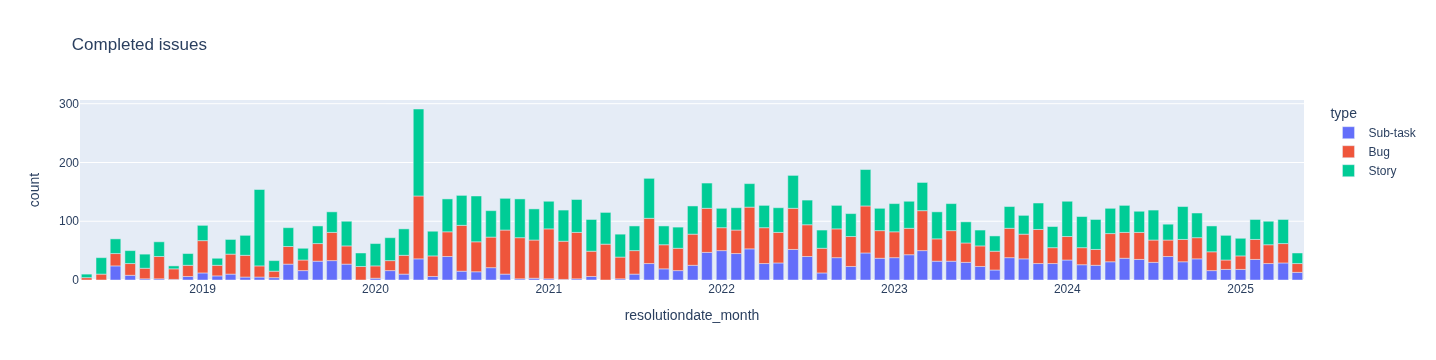

In [5]:
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

px.bar(
    issues_completed.groupBy('resolutiondate_month','type').count().toPandas(),
    x='resolutiondate_month',
    y='count',
    color='type',
    title='Completed issues')

# Heavy open issues

In [24]:
work_hours_threshold = 16
skip_status = ['Backlog','Delivery','Delivered']

issues_open\
.join(ts,ts.jira_id == issues_normalized.key, 'left')\
.groupBy('key','summary','type','priority','status','size','user')\
.agg(f.sum('hours').alias('total_hours'))\
.where(f.col('total_hours') > work_hours_threshold)\
.where(~f.col('status').isin(skip_status))\
.orderBy(f.col('total_hours').desc())\
.toPandas()

,key,summary,type,priority,status,size,user,total_hours
0,CRYP-9217,[WebTP] problemy z performance w webTP,Story,Medium,In Progress,None,PAn,163.50
1,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,Story,Medium,In Review,None,TGa,100.50
2,CRYP-10285,[Wallet monitor] Połączenie z Vaultem,Story,Medium,In Review,M,MRy,89.00
3,CRYP-10472,[LPHS] Złe zachowanie funkcjonalności `trailin...,Bug,High,In testing,None,PGr,86.75
4,CRYP-9477,[CCXT] Dodanie znacznika początku i konca nagr...,Story,Medium,In Review,None,MRy,85.50
5,CRYP-10461,[WebTP] W presetach strategii nie są zapisywan...,Bug,Medium,In testing,None,PAn,78.00
6,CRYP-10257,[Backtest] Wykonywanie symulacji dla listy ins...,Story,Medium,In Progress,None,TGa,65.00
7,CRYP-10311,[Global position manager] Pierwsza wersja,Story,Medium,In Progress,None,PGr,53.00
8,CRYP-8364,[WebTP] UI properties - refactor,Story,Medium,To Do,None,PAn,44.00
9,CRYP-10264,ActiveOrders- Manual,Sub-task,Medium,In Progress,None,PAn,35.00


# Gitlab projects

In [2]:
import pyspark.sql.functions as f
from utils import project_type

projects = spark.read.json('../data/gitlab-projects.json')\
.withColumn('name_with_namespace',f.regexp_replace('name_with_namespace', ' ', ''))\
.withColumn('project_type',project_type(f.col('name_with_namespace')))\
.drop('tag_list')

# Merge requests

In [8]:
from utils import duration_days

mrs = spark.read.json('../data/gitlab-merge-requests.json')\
.where(f.col('state')=='merged')\
.withColumn('created_at',f.col('created_at').cast(TimestampType()))\
.withColumn('updated_at',f.col('updated_at').cast(TimestampType()))\
.withColumn('closed_at',f.col('closed_at').cast(TimestampType()))\
.withColumn('merged_at',f.col('merged_at').cast(TimestampType()))\
.withColumn('month',f.date_trunc('month',f.col('merged_at')))\
.withColumn('duration_days',duration_days('created_at','merged_at'))\
.withColumn('jira_id',f.concat(f.lit('CRYP-'),f.regexp_extract('source_branch', r'(\d+)', 1)))

#mrs.show()

In [9]:
mrs_count = mrs\
.groupBy('month')\
.agg(f.count('*').alias('count'))\
.orderBy(f.col('month').desc())

project_mrs = projects.join(mrs,projects.id == mrs.project_id)

mrs_count_by_type = project_mrs\
.groupBy('month','project_type')\
.agg(f.count('*').alias('count'))\
.orderBy(f.col('month').desc())

In [10]:
px.bar(mrs_count_by_type.toPandas(),x='month',y='count',color='project_type',title='MR count by project type')

In [11]:
mrs_duration = project_mrs\
.groupBy('month','project_type')\
.agg(
    f.avg('duration_days').alias('duration_days_avg'),
    f.min('duration_days').alias('duration_days_min'),
    f.max('duration_days').alias('duration_days_max'),
    f.expr('percentile(duration_days, array(0.25,0.5,0.75,0.9,0.99))').alias('duration_days_pct'))\
.withColumn('duration_days_pct25',f.col('duration_days_pct')[0])\
.withColumn('duration_days_pct50',f.col('duration_days_pct')[1])\
.withColumn('duration_days_pct75',f.col('duration_days_pct')[2])\
.withColumn('duration_days_pct90',f.col('duration_days_pct')[3])\
.withColumn('duration_days_pct99',f.col('duration_days_pct')[4])

In [12]:
px.bar(mrs_duration.toPandas(),x='month',y='duration_days_pct50',color='project_type',title='MR duration pct50',log_y=True,barmode='group')

In [13]:
px.bar(mrs_duration.toPandas(),x='month',y='duration_days_pct75',color='project_type',title='MR duration pct75',log_y=True,barmode='group')

In [14]:
mrs_comments = project_mrs\
.groupBy('month','project_type')\
.agg(
    f.count('*').alias('count'),
    f.sum('user_notes_count').alias('comments'))\
.withColumn('comments_avg',f.col('comments')/f.col('count'))

In [15]:
px.bar(mrs_comments.toPandas(),x='month',y='comments',color='project_type',title='MR comments')

# Commits

In [16]:
commits = spark.read.json('../data/commits/*.json')\
.withColumn('committer',f.split('committer','@')[0])\
.withColumn('createdAt',f.col('createdAt').cast(TimestampType()))\
.withColumn('month',f.date_trunc('month','createdAt'))

project_commits = commits.join(projects,commits.projectId == projects.id)

commits_by_project_type = project_commits\
.groupBy('month','project_type')\
.agg(
    f.count(commits.id).alias('count'),
    f.sum('additions').alias('additions'),
    f.sum('deletions').alias('deletions'))

In [17]:
px.bar(commits_by_project_type.toPandas(),x='month',y='additions',color='project_type',title='Code additions',log_y=True)

In [18]:
px.bar(commits_by_project_type.toPandas(),x='month',y='deletions',color='project_type',title='Deletions',log_y=True)

# KBa

In [34]:
from datetime import datetime,timedelta
import pandas as pd

pd.set_option('display.max_rows', None)

def past_date(days):
    return (datetime.now() - timedelta(days = 180)).replace(hour=0)

issues_normalized\
.join(ts,ts.jira_id == issues_normalized.key, 'left')\
.where(f.col('user')=='KBa')\
.where(f.col('status_changed_at') > past_date(180))\
.orderBy(f.col('status_changed_at').desc())\
.groupBy('key','summary','status','type','priority','size','status_changed_at')\
.agg(f.sum('hours').alias('total_hours'))\
.toPandas()

,key,summary,status,type,priority,size,status_changed_at,total_hours
0,CRYP-10693,Server ccxt2-975 padł,In Progress,Bug,Highest,None,2025-05-16 05:53:16.253,8.0
1,CRYP-9913,[platform-admin] Błędne uprawnienia credential...,Ready to test,Bug,Medium,None,2025-05-15 06:34:40.703,6.5
2,CRYP-10580,[Hurtownia danych] Migracja danych COEFFICIENT...,Delivered,Story,Medium,None,2025-05-13 12:30:11.766,25.0
3,CRYP-10556,[Backtest] Zasilenie danych historycznych od p...,Done,Story,High,None,2025-05-13 06:11:32.732,23.0
4,CRYP-10658,[Liquidty Calculator] Wartości pól w różnych o...,In Progress,Bug,High,None,2025-05-12 12:56:06.411,12.0
5,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,In Review,Story,Medium,None,2025-05-12 12:02:48.857,2.5
6,CRYP-10633,Market Data Recorder - serializacja konsumpcji...,In testing,Bug,Medium,None,2025-05-09 10:30:11.244,7.0
7,CRYP-10651,"[Onetrading] ERROR ""Java heap space""",In testing,Bug,High,None,2025-05-06 12:57:13.306,7.5
8,CRYP-10636,[Liquidty Calculator] Złe korzystanie z coeffi...,Delivered,Bug,Highest,None,2025-05-06 06:59:47.319,2.0
9,CRYP-10632,25.04.2025 - Brak liquidity measures dla częśc...,Done,Bug,Medium,None,2025-05-05 08:57:58.476,4.0
